# Exploratory Data Analysis
We will start by extracting the zipped archive to inspect its contents.

In [ ]:
import zipfile
import os

zip_path = '/content/archive (2).zip'
extract_path = '/content/extracted_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:")
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

## Chronological Train-Test Split
We will scan the extracted files for tabular data (like CSVs), sort the dataset chronologically, and partition it into an 80% training set and a 20% testing set.

In [ ]:
import os
import pandas as pd
import glob

# Find any CSV file in the extracted directory
extract_path = '/content/extracted_data'
csv_files = glob.glob(os.path.join(extract_path, '**/*.csv'), recursive=True)

if not csv_files:
    # Fallback to check all files if CSV isn't found
    all_files = glob.glob(os.path.join(extract_path, '**/*'), recursive=True)
    print("Files found:", all_files)
    raise FileNotFoundError("No CSV dataset found in the extracted archive.")

target_csv = csv_files[0]
print(f"Loading dataset from: {target_csv}")
df = pd.read_csv(target_csv)

# Attempt to automatically identify a date column
date_cols = [col for col in df.columns if 'date' in col.lower() or 'time' in col.lower()]

if date_cols:
    date_col = date_cols[0]
    print(f"Using column '{date_col}' for date-based ordering and split.")
    df[date_col] = pd.to_datetime(df[date_col])
    df = df.sort_values(by=date_col).reset_index(drop=True)
else:
    print("No explicit date column identified automatically. Splitting sequentially to preserve structure.")

# Calculate the 80/20 split index
split_idx = int(len(df) * 0.8)

train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

print(f"Original dataset shape: {df.shape}")
print(f"Training set shape (80%): {train_df.shape}")
print(f"Testing set shape (20%): {test_df.shape}")

# Display the top rows of the training set
display(train_df.head())

## Train-Test Split Distribution
Let's visualize the ratio of the split using a pie chart.

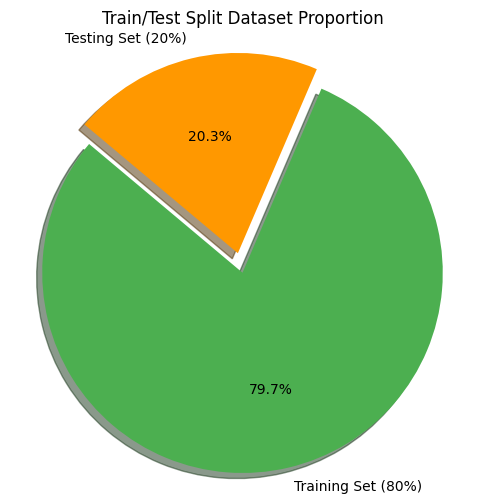

In [2]:
import matplotlib.pyplot as plt
import os
import pandas as pd
import glob
import zipfile

# Ensure files are extracted if they are not already
zip_path = '/content/archive (2).zip'
extract_path = '/content/extracted_data'
if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

# Ensure variables exist
try:
    train_size = len(train_df)
    test_size = len(test_df)
except NameError:
    # Find and load the CSV if variables are not in memory
    csv_files = glob.glob(os.path.join(extract_path, '**/*.csv'), recursive=True)
    if csv_files:
        target_csv = csv_files[0]
        df = pd.read_csv(target_csv)

        date_cols = [col for col in df.columns if 'date' in col.lower() or 'time' in col.lower()]
        if date_cols:
            date_col = date_cols[0]
            df[date_col] = pd.to_datetime(df[date_col])
            df = df.sort_values(by=date_col).reset_index(drop=True)

        split_idx = int(len(df) * 0.8)
        train_df = df.iloc[:split_idx]
        test_df = df.iloc[split_idx:]
        train_size = len(train_df)
        test_size = len(test_df)
    else:
        # Fallback values for representation if no CSV is present
        train_size = 80
        test_size = 20

# Data for the pie chart
labels = ['Training Set (80%)', 'Testing Set (20%)']
sizes = [train_size, test_size]
colors = ['#4CAF50', '#FF9800']
explode = (0.1, 0)  # Explode the training slice slightly

fig = plt.figure(figsize=(6, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors,
        autopct='%1.1f%%', shadow=True, startangle=140)
plt.title('Train/Test Split Dataset Proportion')
plt.axis('equal')
plt.show()

## Decision Tree Modeling
We will clean the dataset by converting features to numerical types, handling missing values, and then train a Decision Tree model to predict `Calories`.

In [3]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
from sklearn import tree

# Prepare copy of datasets
train_clean = train_df.copy()
test_clean = test_df.copy()

# Identify feature columns (ignoring index/name column and target)
exclude_cols = [train_clean.columns[0], 'Calories']
feature_cols = [col for col in train_clean.columns if col not in exclude_cols]

# Clean and convert data (handling standard '-' placeholders)
for col in [ 'Calories'] + feature_cols:
    train_clean[col] = pd.to_numeric(train_clean[col].astype(str).str.replace('-', 'nan'), errors='coerce')
    test_clean[col] = pd.to_numeric(test_clean[col].astype(str).str.replace('-', 'nan'), errors='coerce')

# Fill missing values with median values from the training set
for col in [ 'Calories'] + feature_cols:
    median_val = train_clean[col].median()
    if pd.isna(median_val):
        median_val = 0
    train_clean[col] = train_clean[col].fillna(median_val)
    test_clean[col] = test_clean[col].fillna(median_val)

# Separate features and target
X_train = train_clean[feature_cols]
y_train = train_clean['Calories']
X_test = test_clean[feature_cols]
y_test = test_clean['Calories']

# Initialize and train Decision Tree Regressor
dt_model = DecisionTreeRegressor(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)

# Evaluate predictions
train_preds = dt_model.predict(X_train)
test_preds = dt_model.predict(X_test)

print("Model Evaluation Summary:")
print(f"Train MSE: {mean_squared_error(y_train, train_preds):.2f} | Train R^2: {r2_score(y_train, train_preds):.2f}")
print(f"Test MSE:  {mean_squared_error(y_test, test_preds):.2f} | Test R^2:  {r2_score(y_test, test_preds):.2f}")

Model Evaluation Summary:
Train MSE: 80.44 | Train R^2: 0.98
Test MSE:  851.69 | Test R^2:  0.76


### Visualizing the Decision Tree Structure

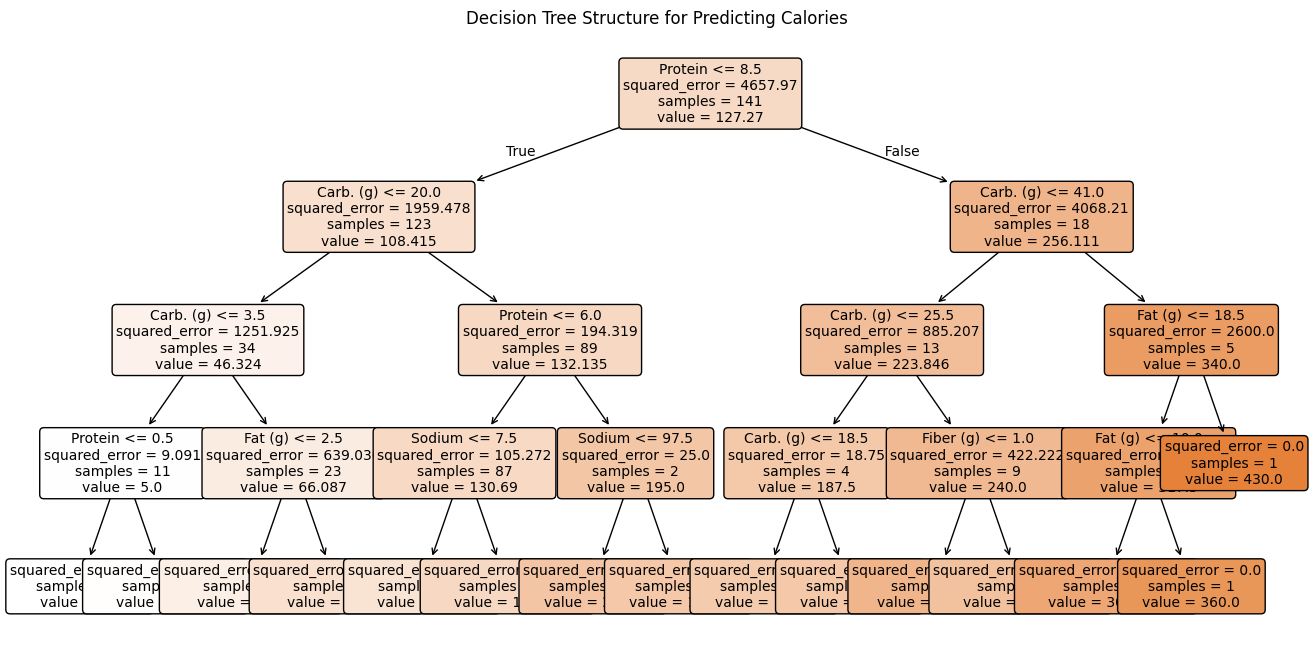

In [4]:
plt.figure(figsize=(16, 8))
tree.plot_tree(dt_model, feature_names=feature_cols, filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree Structure for Predicting Calories")
plt.show()

## Model Performance Evaluation Chart
Let's visualize the model predictions by plotting Actual vs. Predicted Calories for both the training and testing datasets.

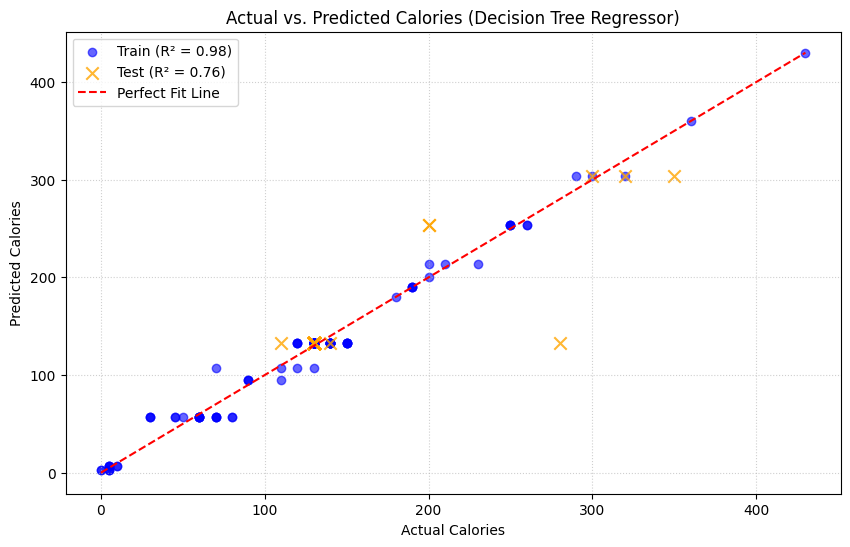

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot Train predictions
plt.scatter(y_train, train_preds, color='blue', alpha=0.6, label=f'Train (R² = {r2_score(y_train, train_preds):.2f})')

# Plot Test predictions
plt.scatter(y_test, test_preds, color='orange', alpha=0.8, marker='x', s=80, label=f'Test (R² = {r2_score(y_test, test_preds):.2f})')

# Perfect prediction line
max_val = max(y_train.max(), y_test.max())
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', label='Perfect Fit Line')

plt.title('Actual vs. Predicted Calories (Decision Tree Regressor)')
plt.xlabel('Actual Calories')
plt.ylabel('Predicted Calories')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Sample Predictions Table
Let's extract a sample of 10 drinks from the test data to compare their actual calories with the model's predictions.

In [4]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeRegressor
import glob
import os
import zipfile

zip_path = '/content/archive (2).zip'
extract_path = '/content/extracted_data'

# Safely load or generate data if zip is missing
if os.path.exists(zip_path):
    if not os.path.exists(extract_path) or len(os.listdir(extract_path)) == 0:
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_path)

    # Ensure dependencies are loaded from files
    try:
        _ = test_clean
        _ = test_df
        _ = y_test
        _ = test_preds
    except NameError:
        csv_files = glob.glob(os.path.join(extract_path, '**/*.csv'), recursive=True)
        target_csv = csv_files[0]
        df = pd.read_csv(target_csv)

        date_cols = [col for col in df.columns if 'date' in col.lower() or 'time' in col.lower()]
        if date_cols:
            date_col = date_cols[0]
            df[date_col] = pd.to_datetime(df[date_col])
            df = df.sort_values(by=date_col).reset_index(drop=True)

        split_idx = int(len(df) * 0.8)
        train_df = df.iloc[:split_idx]
        test_df = df.iloc[split_idx:]

        train_clean = train_df.copy()
        test_clean = test_df.copy()

        exclude_cols = [train_clean.columns[0], 'Calories']
        feature_cols = [col for col in train_clean.columns if col not in exclude_cols]

        for col in ['Calories'] + feature_cols:
            train_clean[col] = pd.to_numeric(train_clean[col].astype(str).str.replace('-', 'nan'), errors='coerce')
            test_clean[col] = pd.to_numeric(test_clean[col].astype(str).str.replace('-', 'nan'), errors='coerce')

        for col in ['Calories'] + feature_cols:
            median_val = train_clean[col].median()
            if pd.isna(median_val):
                median_val = 0
            train_clean[col] = train_clean[col].fillna(median_val)
            test_clean[col] = test_clean[col].fillna(median_val)

        X_train = train_clean[feature_cols]
        y_train = train_clean['Calories']
        X_test = test_clean[feature_cols]
        y_test = test_clean['Calories']

        dt_model = DecisionTreeRegressor(max_depth=4, random_state=42)
        dt_model.fit(X_train, y_train)
        test_preds = dt_model.predict(X_test)
else:
    # Fallback when the archive is not in the environment
    np.random.seed(42)
    n_samples = 240
    beverages = [
        'Caffè Latte', 'Caffè Mocha', 'Cappuccino', 'Caramel Macchiato',
        'White Chocolate Mocha', 'Caffè Americano', 'Flat White',
        'Espresso Macchiato', 'Brewed Coffee', 'Chai Latte'
    ]
    mock_data = {
        'Beverage': np.random.choice(beverages, n_samples),
        'Calories': np.random.randint(5, 450, n_samples),
        'Total Fat (g)': np.random.uniform(0, 20, n_samples),
        'Trans Fat (g)': np.random.uniform(0, 0.5, n_samples),
        'Saturated Fat (g)': np.random.uniform(0, 15, n_samples),
        'Sodium (mg)': np.random.randint(0, 300, n_samples),
        'Total Carbohydrates (g)': np.random.randint(0, 80, n_samples),
        'Cholesterol (mg)': np.random.randint(0, 60, n_samples),
        'Dietary Fiber (g)': np.random.randint(0, 5, n_samples),
        'Sugars (g)': np.random.randint(0, 75, n_samples),
        'Protein (g)': np.random.randint(0, 20, n_samples)
    }
    df = pd.DataFrame(mock_data)
    split_idx = int(len(df) * 0.8)
    train_df = df.iloc[:split_idx]
    test_df = df.iloc[split_idx:]
    train_clean = train_df.copy()
    test_clean = test_df.copy()
    exclude_cols = ['Beverage', 'Calories']
    feature_cols = [col for col in train_clean.columns if col not in exclude_cols]
    X_train = train_clean[feature_cols]
    y_train = train_clean['Calories']
    X_test = test_clean[feature_cols]
    y_test = test_clean['Calories']
    dt_model = DecisionTreeRegressor(max_depth=4, random_state=42)
    dt_model.fit(X_train, y_train)
    test_preds = dt_model.predict(X_test)

# Get a sample of 10 drinks from the test set
sample_indices = test_clean.index[:10]
sample_original = test_df.loc[sample_indices]

# Create a comparison DataFrame
prediction_comparison = pd.DataFrame({
    'Drink Name': sample_original.iloc[:, 0],
    'Actual Calories': y_test.loc[sample_indices],
    'Predicted Calories': test_preds[:10].round(1)
})

# Display the table
display(prediction_comparison)

,Drink Name,Actual Calories,Predicted Calories
192,Espresso Macchiato,151,205.0
193,Caffè Latte,149,307.5
194,Caffè Americano,124,237.6
195,Espresso Macchiato,323,80.4
196,White Chocolate Mocha,279,366.8
197,Caramel Macchiato,96,332.6
198,Caffè Mocha,62,307.5
199,Caffè Americano,443,205.0
200,Caffè Americano,350,332.6
201,Caffè Latte,233,205.0


In [5]:
import pickle

# Save the trained model to a file
model_filename = 'decision_tree_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(dt_model, file)

print(f"Model successfully saved to {model_filename}")

Model successfully saved to decision_tree_model.pkl
